# A2 — No Spatial Modality Gate — 5-Fold OOF Validation

This notebook performs the official **80-patient out-of-fold evaluation** using the five completed Fold 0–4 training outputs.

### Kaggle inputs
1. Original **MS3SEG** dataset
2. The five completed **A2 — No Spatial Modality Gate Fold 0–4 TRANSFER outputs**

The frozen 20-patient test set is protected and is **not evaluated** here.


In [1]:
from __future__ import annotations

import os
import re
import gc
import io
import json
import math
import random
import warnings
import hashlib
import zipfile
import shutil
from functools import lru_cache
from pathlib import Path
from typing import Literal

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

from scipy import ndimage
from scipy.optimize import linear_sum_assignment

import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
INFERENCE_BATCH_SIZE = 4
LOCKED_TEST_EVALUATION = False
EXPECTED_SPLIT_SHA256 = "d5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459"

OUTPUT_DIR = Path("/kaggle/working/a2_no_spatial_gate_5fold_oof_validation")
FIGURE_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
if DEVICE.type != "cuda":
    warnings.warn("A GPU is strongly recommended. Select a T4 GPU in Kaggle Settings.")

if LOCKED_TEST_EVALUATION:
    raise RuntimeError("Locked-test evaluation is intentionally disabled in the OOF validation notebook.")


Device: cuda


In [2]:
def discover_ms3seg_root():
    required = {"MS_100_patient_preprocessed", "MS_100_patient_masks"}

    preferred = [
        Path("/kaggle/input/ms3seg/MS3SEG"),
        Path("/kaggle/input/ms3seg"),
        Path("/kaggle/input/datasets/saifsamiul/ms3seg/MS3SEG"),
    ]

    for candidate in preferred:
        if not candidate.exists() or not candidate.is_dir():
            continue
        names = {p.name for p in candidate.iterdir() if p.is_dir()}
        if required.issubset(names):
            return candidate

    input_root = Path("/kaggle/input")
    for preprocessed in input_root.rglob("MS_100_patient_preprocessed"):
        candidate = preprocessed.parent
        if (candidate / "MS_100_patient_masks").exists():
            return candidate

    raise FileNotFoundError(
        "MS3SEG was not found. Attach the original MS3SEG Kaggle dataset."
    )


TRANSFER_PREFIX = "MS3SEG_V281_ABL_A2_NO_SPATIAL_GATE_FOLD"
METADATA_MARKER = "ablation-a2_no_spatial_gate".lower()


def discover_all_fold_bundles():
    input_root = Path("/kaggle/input")
    extraction_root = Path("/kaggle/working/oof_checkpoint_extract")
    extraction_root.mkdir(parents=True, exist_ok=True)

    bundles = {}

    for fold in range(5):
        zip_candidates = [
            p for p in input_root.rglob("*.zip")
            if p.is_file()
            and p.name.startswith(
                f"{TRANSFER_PREFIX}{fold}_FULL60_TRANSFER"
            )
        ]

        if zip_candidates:
            zip_path = sorted(
                zip_candidates,
                key=lambda p: p.stat().st_size,
                reverse=True,
            )[0]

            fold_dir = extraction_root / f"fold{fold}"
            if fold_dir.exists():
                shutil.rmtree(fold_dir)
            fold_dir.mkdir(parents=True, exist_ok=True)

            with zipfile.ZipFile(zip_path, "r") as zf:
                zf.extractall(fold_dir)

            checkpoint_hits = list(fold_dir.rglob("best_model.pt"))
            split_hits = list(
                fold_dir.rglob("patient_level_5fold_split.csv")
            )

            if len(checkpoint_hits) != 1 or len(split_hits) != 1:
                raise FileNotFoundError(
                    f"Fold {fold} transfer ZIP must contain exactly one "
                    "best_model.pt and patient_level_5fold_split.csv: "
                    f"{zip_path}"
                )

            checkpoint = checkpoint_hits[0]
            split_path = split_hits[0]
            metadata_path = checkpoint.parent / "transfer_metadata.json"

            bundles[fold] = {
                "checkpoint": checkpoint,
                "split": split_path,
                "metadata": metadata_path if metadata_path.exists() else None,
                "source": zip_path,
            }
            continue

        # Support Kaggle datasets where transfer ZIPs were already extracted.
        direct_candidates = []

        for meta_path in input_root.rglob("transfer_metadata.json"):
            try:
                metadata = json.loads(
                    meta_path.read_text(encoding="utf-8")
                )
            except Exception:
                continue

            meta_fold = metadata.get("fold", None)
            model_text = str(metadata.get("model", "")).lower()
            run_text = str(metadata.get("run_directory", "")).lower()
            parent_text = str(meta_path.parent).lower()

            belongs_to_model = (
                METADATA_MARKER in model_text
                or METADATA_MARKER in run_text
                or METADATA_MARKER in parent_text
            )

            if not belongs_to_model:
                continue

            try:
                meta_fold = int(meta_fold)
            except Exception:
                continue

            if meta_fold != fold:
                continue

            checkpoint = meta_path.parent / "best_model.pt"
            split_path = meta_path.parent / "patient_level_5fold_split.csv"

            if checkpoint.exists() and split_path.exists():
                direct_candidates.append(
                    (checkpoint, split_path, meta_path)
                )

        if len(direct_candidates) != 1:
            raise FileNotFoundError(
                f"Fold {fold} checkpoint not found uniquely for this model. "
                f"Attach the five {TRANSFER_PREFIX}0..4_FULL60_TRANSFER ZIPs "
                "or one Kaggle dataset containing those extracted outputs."
            )

        checkpoint, split_path, metadata_path = direct_candidates[0]
        bundles[fold] = {
            "checkpoint": checkpoint,
            "split": split_path,
            "metadata": metadata_path,
            "source": checkpoint.parent,
        }

    return bundles


DATA_ROOT = discover_ms3seg_root()
CHECKPOINT_BUNDLES = discover_all_fold_bundles()

PREPROCESSED_DIR = DATA_ROOT / "MS_100_patient_preprocessed"
MASKS_DIR = DATA_ROOT / "MS_100_patient_masks"

print("Dataset root:", DATA_ROOT)
for fold, info in CHECKPOINT_BUNDLES.items():
    print(f"Fold {fold} checkpoint source:", info["source"])


Dataset root: /kaggle/input/datasets/saifsamiul/ms3seg/MS3SEG
Fold 0 checkpoint source: /kaggle/input/datasets/saifsoft/a2-fold04-outputs/MS3SEG_V281_ABL_A2_NO_SPATIAL_GATE_FOLD0_FULL60_TRANSFER
Fold 1 checkpoint source: /kaggle/input/datasets/saifsoft/a2-fold04-outputs/MS3SEG_V281_ABL_A2_NO_SPATIAL_GATE_FOLD1_FULL60_TRANSFER
Fold 2 checkpoint source: /kaggle/input/datasets/saifsoft/a2-fold04-outputs/MS3SEG_V281_ABL_A2_NO_SPATIAL_GATE_FOLD2_FULL60_TRANSFER
Fold 3 checkpoint source: /kaggle/input/datasets/saifsoft/a2-fold04-outputs/MS3SEG_V281_ABL_A2_NO_SPATIAL_GATE_FOLD3_FULL60_TRANSFER
Fold 4 checkpoint source: /kaggle/input/datasets/saifsoft/a2-fold04-outputs/MS3SEG_V281_ABL_A2_NO_SPATIAL_GATE_FOLD4_FULL60_TRANSFER


In [3]:
mask_roots = [
    path
    for path in MASKS_DIR.iterdir()
    if path.is_dir()
]


def select_mask_root(kind):
    if kind == "vent":
        matches = [
            path
            for path in mask_roots
            if "vent" in path.name.lower()
        ]

    elif kind == "nwmh":
        matches = [
            path
            for path in mask_roots
            if (
                "nwmh" in path.name.lower()
                or "normal" in path.name.lower()
            )
            and "abwmh" not in path.name.lower()
            and "abnormal" not in path.name.lower()
        ]

    else:
        matches = [
            path
            for path in mask_roots
            if (
                "abwmh" in path.name.lower()
                or "abnormal" in path.name.lower()
            )
        ]

    if len(matches) != 1:
        raise RuntimeError(
            f"Expected one {kind} mask root, found: {matches}"
        )

    return matches[0]


VENT_ROOT = select_mask_root("vent")
NWMH_ROOT = select_mask_root("nwmh")
ABWMH_ROOT = select_mask_root("abwmh")


def find_unique_file(
    folder,
    patterns,
    description,
):
    found = []

    for pattern in patterns:
        found.extend(
            folder.glob(pattern)
        )

    unique = []
    seen = set()

    for path in found:
        if (
            path.is_file()
            and path not in seen
        ):
            unique.append(path)
            seen.add(path)

    if len(unique) != 1:
        raise FileNotFoundError(
            f"{description}: expected one file in {folder}; "
            f"found {len(unique)}: {unique}"
        )

    return unique[0]


patient_dirs = sorted(
    path
    for path in PREPROCESSED_DIR.iterdir()
    if (
        path.is_dir()
        and re.fullmatch(
            r"\d{3}",
            path.name,
        )
    )
)

records = []

for patient_dir in patient_dirs:
    patient_id = patient_dir.name

    records.append({
        "patient_id": patient_id,
        "flair": str(
            find_unique_file(
                patient_dir,
                [
                    f"{patient_id}_FLAIR.nii",
                    f"{patient_id}_FLAIR.nii.gz",
                ],
                f"{patient_id} FLAIR",
            )
        ),
        "t1": str(
            find_unique_file(
                patient_dir,
                [
                    f"{patient_id}_T1WI_reg.nii",
                    f"{patient_id}_T1WI_reg.nii.gz",
                    "*T1*reg*.nii*",
                ],
                f"{patient_id} T1",
            )
        ),
        "t2": str(
            find_unique_file(
                patient_dir,
                [
                    f"{patient_id}_T2WI_reg.nii",
                    f"{patient_id}_T2WI_reg.nii.gz",
                    "*T2*reg*.nii*",
                ],
                f"{patient_id} T2",
            )
        ),
        "vent": str(
            find_unique_file(
                VENT_ROOT / patient_id,
                [
                    f"{patient_id}_Vent_Mask.nii",
                    f"{patient_id}_Vent_Mask.nii.gz",
                    "*Vent*Mask*.nii*",
                ],
                f"{patient_id} ventricle mask",
            )
        ),
        "nwmh": str(
            find_unique_file(
                NWMH_ROOT / patient_id,
                [
                    f"{patient_id}_nWMH_Mask.nii",
                    f"{patient_id}_nWMH_Mask.nii.gz",
                    "*nWMH*Mask*.nii*",
                ],
                f"{patient_id} normal-WMH mask",
            )
        ),
        "abwmh": str(
            find_unique_file(
                ABWMH_ROOT / patient_id,
                [
                    f"{patient_id}_abWMH_Mask.nii",
                    f"{patient_id}_abWMH_Mask.nii.gz",
                    "*abWMH*Mask*.nii*",
                ],
                f"{patient_id} abnormal-WMH mask",
            )
        ),
    })


manifest = (
    pd.DataFrame(records)
    .sort_values("patient_id")
    .reset_index(drop=True)
)

manifest["patient_id"] = (
    manifest["patient_id"]
    .astype(str)
    .str.zfill(3)
)

manifest_by_id = manifest.set_index("patient_id")

print("Patients found:", len(manifest))

if len(manifest) != 100:
    warnings.warn(
        f"Expected 100 patients but found {len(manifest)}."
    )

display(manifest.head())

Patients found: 100


,patient_id,flair,t1,t2,vent,nwmh,abwmh
0,001,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
1,002,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
2,003,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
3,004,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
4,005,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...


In [4]:
# Verify that every checkpoint bundle carries the exact same frozen split.
split_hashes = {}
split_frames = {}

for fold, info in CHECKPOINT_BUNDLES.items():
    raw = info["split"].read_bytes()
    sha = hashlib.sha256(raw).hexdigest()
    split_hashes[fold] = sha

    frame = pd.read_csv(info["split"], dtype={"patient_id": str})
    frame["patient_id"] = frame["patient_id"].astype(str).str.zfill(3)
    split_frames[fold] = frame

print("Split hashes:", split_hashes)

if len(set(split_hashes.values())) != 1:
    raise RuntimeError("The five checkpoint bundles do not contain identical patient splits.")

if next(iter(split_hashes.values())) != EXPECTED_SPLIT_SHA256:
    raise RuntimeError(
        "Frozen split checksum differs from the completed Fold-0 experiment. "
        "Do not evaluate until the correct checkpoint packages are attached."
    )

split_df = split_frames[0].copy()

required_columns = {"patient_id", "fold", "role"}
missing = required_columns - set(split_df.columns)
if missing:
    raise ValueError(f"Frozen split is missing columns: {sorted(missing)}")

locked_test_ids = sorted(
    split_df.loc[split_df["role"] == "test", "patient_id"].astype(str).str.zfill(3).unique()
)

if len(locked_test_ids) != 20:
    raise RuntimeError(f"Expected 20 locked-test patients, found {len(locked_test_ids)}.")

validation_ids_by_fold = {}

for fold in range(5):
    val_ids = sorted(
        split_df.loc[
            (split_df["fold"] == fold) & (split_df["role"] == "val"),
            "patient_id",
        ].astype(str).str.zfill(3).unique()
    )
    train_ids = sorted(
        split_df.loc[
            (split_df["fold"] == fold) & (split_df["role"] == "train"),
            "patient_id",
        ].astype(str).str.zfill(3).unique()
    )

    if len(train_ids) != 64 or len(val_ids) != 16:
        raise RuntimeError(
            f"Fold {fold} split is invalid: train={len(train_ids)}, val={len(val_ids)}."
        )
    if set(train_ids) & set(val_ids):
        raise RuntimeError(f"Fold {fold} train/validation overlap detected.")
    if set(val_ids) & set(locked_test_ids):
        raise RuntimeError(f"Fold {fold} validation/locked-test overlap detected.")

    validation_ids_by_fold[fold] = val_ids

all_oof_ids = [pid for fold in range(5) for pid in validation_ids_by_fold[fold]]

if len(all_oof_ids) != 80 or len(set(all_oof_ids)) != 80:
    raise RuntimeError("The 5-fold validation union must contain each of the 80 development patients exactly once.")

dataset_ids = set(manifest["patient_id"])
split_ids = set(split_df["patient_id"].astype(str).str.zfill(3))
if dataset_ids != split_ids:
    raise RuntimeError("MS3SEG patient IDs do not match the frozen checkpoint split.")

print("Frozen split verification: PASSED")
print("OOF development patients:", len(all_oof_ids))
print("Locked-test patients protected:", len(locked_test_ids))


Split hashes: {0: 'd5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459', 1: 'd5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459', 2: 'd5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459', 3: 'd5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459', 4: 'd5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459'}
Frozen split verification: PASSED
OOF development patients: 80
Locked-test patients protected: 20


In [5]:
@lru_cache(maxsize=48)
def load_volume(path):
    return np.asarray(
        nib.load(
            path,
            mmap=True,
        ).dataobj,
        dtype=np.float32,
    )


@lru_cache(maxsize=36)
def load_normalized_volume(path):
    array = load_volume(path).copy()

    finite = np.isfinite(array)
    nonzero = (
        finite
        & (
            np.abs(array)
            > 1e-6
        )
    )

    if nonzero.sum() < 100:
        return np.nan_to_num(
            array
        ).astype(np.float32)

    low, high = np.percentile(
        array[nonzero],
        [
            0.5,
            99.5,
        ],
    )

    high = max(
        high,
        low + 1.0,
    )

    array = np.clip(
        array,
        low,
        high,
    )

    array = (
        array
        - array[nonzero].mean()
    ) / (
        array[nonzero].std()
        + 1e-6
    )

    array[~finite] = 0.0

    return array.astype(
        np.float32
    )


@lru_cache(maxsize=48)
def load_binary_mask(path):
    return (
        load_volume(path)
        > 0
    ).astype(np.uint8)


def compose_target(row):
    ventricle = load_binary_mask(
        row.vent
    )

    normal_wmh = load_binary_mask(
        row.nwmh
    )

    abnormal_wmh = load_binary_mask(
        row.abwmh
    )

    target = np.zeros(
        ventricle.shape,
        dtype=np.uint8,
    )

    target[
        ventricle
        > 0
    ] = 1

    target[
        normal_wmh
        > 0
    ] = 2

    target[
        abnormal_wmh
        > 0
    ] = 3

    return target


def triplet(
    volume,
    slice_index,
):
    depth = volume.shape[2]

    indices = [
        max(
            0,
            slice_index - 1,
        ),
        slice_index,
        min(
            depth - 1,
            slice_index + 1,
        ),
    ]

    return np.stack(
        [
            volume[
                :,
                :,
                index,
            ]
            for index in indices
        ],
        axis=0,
    )


def build_patient_inputs(row):
    flair = load_normalized_volume(
        row.flair
    )

    t1 = load_normalized_volume(
        row.t1
    )

    t2 = load_normalized_volume(
        row.t2
    )

    depth = flair.shape[2]

    inputs = []

    for slice_index in range(depth):
        inputs.append(
            np.concatenate(
                [
                    triplet(
                        flair,
                        slice_index,
                    ),
                    triplet(
                        t1,
                        slice_index,
                    ),
                    triplet(
                        t2,
                        slice_index,
                    ),
                ],
                axis=0,
            )
        )

    return np.stack(
        inputs,
        axis=0,
    ).astype(np.float32)

In [6]:
class ConvNormAct(nn.Module):
    def __init__(self, in_ch, out_ch, k=3, stride=1, groups=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, k, stride=stride, padding=k//2, groups=groups, bias=False),
            nn.GroupNorm(min(8, out_ch), out_ch),
            nn.SiLU(inplace=True),
        )
    def forward(self, x): return self.net(x)

class ResidualBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.c1 = ConvNormAct(ch, ch)
        self.c2 = nn.Sequential(nn.Conv2d(ch, ch, 3, padding=1, bias=False),
                                nn.GroupNorm(min(8, ch), ch))
        self.act = nn.SiLU(inplace=True)
    def forward(self, x): return self.act(x + self.c2(self.c1(x)))

class SE(nn.Module):
    def __init__(self, ch, r=8):
        super().__init__()
        h = max(8, ch // r)
        self.net = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(ch, h, 1),
                                 nn.SiLU(inplace=True), nn.Conv2d(h, ch, 1), nn.Sigmoid())
    def forward(self, x): return x * self.net(x)

class ModalityStem(nn.Module):
    def __init__(self, out_ch):
        super().__init__()
        self.net = nn.Sequential(ConvNormAct(3, out_ch), ResidualBlock(out_ch), SE(out_ch))
    def forward(self, x): return self.net(x)

def _safe_groups(channels, preferred=8):
    for g in (preferred, 4, 2, 1):
        if channels % g == 0:
            return g
    return 1

class ModalityGatedFusion(nn.Module):
    """
    Ablation A2: learned spatial modality gating removed.
    FLAIR/T1/T2 modality stems are fused using a fixed equal average.
    """
    def __init__(self, ch):
        super().__init__()
        self.refine = ResidualBlock(ch)

    def forward(self, f, t1, t2):
        fused = (f + t1 + t2) / 3.0
        weights = torch.full(
            (f.shape[0], 3),
            1.0 / 3.0,
            device=f.device,
            dtype=f.dtype,
        )
        return self.refine(fused), weights


class DownBlock(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.net = nn.Sequential(ConvNormAct(i, o, stride=2), ResidualBlock(o))
    def forward(self, x): return self.net(x)

class UpBlock(nn.Module):
    def __init__(self, i, s, o):
        super().__init__()
        self.net = nn.Sequential(ConvNormAct(i + s, o), ResidualBlock(o))
    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return self.net(torch.cat([x, skip], 1))

class AdaptiveAnisotropicContext(nn.Module):
    def __init__(self, ch):
        super().__init__()
        b = ch // 4
        self.reduce = ConvNormAct(ch, b, 1)
        self.branches = nn.ModuleList([
            nn.Sequential(nn.Conv2d(b, b, 3, padding=d, dilation=d, groups=b, bias=False),
                          nn.GroupNorm(min(8, b), b), nn.SiLU(inplace=True))
            for d in (1, 2, 4, 6)
        ])
        self.mix = nn.Sequential(nn.Conv2d(b * 4, ch, 1, bias=False),
                                 nn.GroupNorm(min(8, ch), ch), nn.SiLU(inplace=True))
        self.se = SE(ch)
    def forward(self, x):
        r = self.reduce(x)
        y = self.se(self.mix(torch.cat([b(r) for b in self.branches], 1)))
        return x + y

class VentiMorphRefiner(nn.Module):
    def __init__(
        self,
        ch,
        mode: Literal["none", "vent", "distance", "directional"],
        max_residual: float = 0.25,
        stop_gradient_guidance: bool = True,
    ):
        super().__init__()
        self.mode = mode
        self.max_residual = float(max_residual)
        self.stop_gradient_guidance = bool(stop_gradient_guidance)
        self.vent_head = nn.Conv2d(ch, 1, 1)
        extras = {"none": 0, "vent": 1, "distance": 5, "directional": 9}[mode]
        self.orientation_head = nn.Conv2d(ch, 2, 1) if mode == "directional" else None
        self.refine = nn.Identity() if mode == "none" else nn.Sequential(
            ConvNormAct(ch + extras, ch), ResidualBlock(ch)
        )

        # Exact identity at initialization + hard amplitude cap.
        self.correction_gate = nn.Conv2d(ch, ch, 1) if mode != "none" else None
        if self.correction_gate is not None:
            nn.init.zeros_(self.correction_gate.weight)
            nn.init.zeros_(self.correction_gate.bias)

        sx = torch.tensor([[-1.,0.,1.],[-2.,0.,2.],[-1.,0.,1.]]).view(1,1,3,3)
        sy = torch.tensor([[-1.,-2.,-1.],[0.,0.,0.],[1.,2.,1.]]).view(1,1,3,3)
        self.register_buffer("sobel_x", sx)
        self.register_buffer("sobel_y", sy)

    def forward(self, feat):
        v_logit = self.vent_head(feat)
        v = torch.sigmoid(v_logit)
        relation = {"vent_logits": v_logit, "vent_prob": v}

        if self.mode == "none":
            return feat, relation

        # v2.8.1: segmentation refinement consumes the current anatomical
        # prediction but does not back-propagate its segmentation gradient
        # through the ventricle head. The ventricle head remains trainable
        # through the explicit auxiliary ventricle loss.
        guide_v = v.detach() if self.stop_gradient_guidance else v

        if self.mode == "vent":
            correction = self.correction_gate(
                self.refine(torch.cat([feat, guide_v], 1))
            )
            return feat + torch.tanh(correction) * self.max_residual, relation

        e1 = F.max_pool2d(guide_v, 7, 1, 3)
        e2 = F.max_pool2d(guide_v, 21, 1, 10)
        near = torch.clamp(e1 - guide_v, 0, 1)
        mid = torch.clamp(e2 - e1, 0, 1)
        far = torch.clamp(1 - e2, 0, 1)
        dist = 0.2 * near + 0.6 * mid + far
        relation.update({"near": near, "mid": mid, "far": far, "soft_distance": dist})
        extras = [guide_v, near, mid, far, dist]

        if self.mode == "directional":
            normal = torch.cat([
                F.conv2d(dist, self.sobel_x, padding=1),
                F.conv2d(dist, self.sobel_y, padding=1),
            ], 1)
            normal = F.normalize(normal, dim=1, eps=1e-6)
            orient = F.normalize(self.orientation_head(feat), dim=1, eps=1e-6)
            radial = torch.abs((normal * orient).sum(1, keepdim=True))
            tangential = 1 - radial
            relation.update({
                "normal_x": normal[:,0:1], "normal_y": normal[:,1:2],
                "orientation_x": orient[:,0:1], "orientation_y": orient[:,1:2],
                "radial": radial, "tangential": tangential,
            })
            extras += [normal[:,0:1], normal[:,1:2], radial, tangential]

        correction = self.correction_gate(
            self.refine(torch.cat([feat] + extras, 1))
        )
        return feat + torch.tanh(correction) * self.max_residual, relation


class RelationConditionedPrototypeBank(nn.Module):
    # Retained only for later ablation work; disabled in the v2.8.1 primary run.
    def __init__(self, dim=32, temperature=0.1):
        super().__init__()
        self.temperature = temperature
        self.prototypes = nn.Parameter(F.normalize(torch.randn(2, 3, dim), dim=-1))

    def loss(self, embedding, target, region, max_samples=4096):
        feat = embedding.permute(0, 2, 3, 1)
        idx = ((target == 2) | (target == 3)).nonzero(as_tuple=False)
        if idx.numel() == 0:
            return embedding.sum() * 0
        if idx.shape[0] > max_samples:
            idx = idx[torch.randperm(idx.shape[0], device=idx.device)[:max_samples]]
        b, y, x = idx[:,0], idx[:,1], idx[:,2]
        f = F.normalize(feat[b, y, x], dim=1)
        label = (target[b, y, x] == 3).long()
        r = region[b, y, x].clamp(0, 2).long()
        p = F.normalize(self.prototypes, dim=-1)[:, r, :].permute(1, 0, 2)
        logits = torch.einsum("nd,ncd->nc", f, p) / self.temperature
        return F.cross_entropy(logits, label)


class VentiMorphRelNet(nn.Module):
    def __init__(
        self,
        base=24,
        num_classes=4,
        use_multimodal=True,
        use_context=True,
        guidance_mode="directional",
        mid_guidance_mode="vent",
        use_prototypes=False,
        use_uncertainty=False,
        deep_supervision=True,
        emb_dim=32,
        mid_relation_residual=0.15,
        final_relation_residual=0.25,
    ):
        super().__init__()
        self.use_multimodal = use_multimodal
        self.use_prototypes = use_prototypes
        self.use_uncertainty = use_uncertainty
        self.deep_supervision = deep_supervision

        self.flair_stem, self.t1_stem, self.t2_stem = [ModalityStem(base) for _ in range(3)]
        self.fusion = ModalityGatedFusion(base)

        self.e0 = nn.Sequential(ConvNormAct(base, 32), ResidualBlock(32))
        self.e1, self.e2, self.e3, self.e4 = (
            DownBlock(32,64), DownBlock(64,128), DownBlock(128,192), DownBlock(192,256)
        )
        self.context = AdaptiveAnisotropicContext(256) if use_context else ResidualBlock(256)
        self.drop = nn.Dropout2d(0.1)
        self.d3, self.d2, self.d1, self.d0 = (
            UpBlock(256,192,192), UpBlock(192,128,128),
            UpBlock(128,64,64), UpBlock(64,32,32)
        )

        # v2.8.1: coarse decoder gets only robust ventricle guidance.
        # Distance/directional morphology is injected only at full resolution.
        self.mid_guide = VentiMorphRefiner(
            128, mid_guidance_mode,
            max_residual=mid_relation_residual,
            stop_gradient_guidance=True,
        )
        self.final_guide = VentiMorphRefiner(
            32, guidance_mode,
            max_residual=final_relation_residual,
            stop_gradient_guidance=True,
        )

        # Prototype/evidential branches are optional research ablations, not
        # part of the primary segmentation-first v2.8.1 training objective.
        self.embedding = (
            nn.Sequential(ConvNormAct(32, emb_dim), nn.Conv2d(emb_dim, emb_dim, 1))
            if use_prototypes else None
        )
        self.prototype_bank = (
            RelationConditionedPrototypeBank(emb_dim) if use_prototypes else None
        )
        self.evidence_head = nn.Conv2d(32, num_classes, 1) if use_uncertainty else None

        self.seg_head = nn.Conv2d(32, num_classes, 1)

        if self.deep_supervision:
            self.aux_head_d2 = nn.Conv2d(128, num_classes, 1)
            self.aux_head_d1 = nn.Conv2d(64, num_classes, 1)

    def forward(self, x):
        if x.ndim != 4 or x.shape[1] != 9:
            raise ValueError(f"Expected [B,9,H,W], got {tuple(x.shape)}")

        f = self.flair_stem(x[:,0:3])
        t1 = self.t1_stem(x[:,3:6]) if self.use_multimodal else torch.zeros_like(f)
        t2 = self.t2_stem(x[:,6:9]) if self.use_multimodal else torch.zeros_like(f)
        fused, weights = self.fusion(f, t1, t2)

        e0 = self.e0(fused)
        e1 = self.e1(e0)
        e2 = self.e2(e1)
        e3 = self.e3(e2)
        e4 = self.drop(self.context(self.e4(e3)))

        d3 = self.d3(e4, e3)
        d2, mid_rel = self.mid_guide(self.d2(d3, e2))
        d1 = self.d1(d2, e1)
        d0, final_rel = self.final_guide(self.d0(d1, e0))

        logits = self.seg_head(d0)
        emb = self.embedding(d0) if self.embedding is not None else None

        evidence = F.softplus(self.evidence_head(d0)) if self.evidence_head is not None else None
        alpha = evidence + 1 if evidence is not None else None
        uncertainty = 4.0 / alpha.sum(1, keepdim=True) if alpha is not None else None

        aux_logits_d2 = self.aux_head_d2(d2) if self.deep_supervision else None
        aux_logits_d1 = self.aux_head_d1(d1) if self.deep_supervision else None

        return {
            "segmentation_logits": logits,
            "embedding": emb,
            "modality_weights": weights,
            "mid_relation": mid_rel,
            "final_relation": final_rel,
            "evidence": evidence,
            "alpha": alpha,
            "uncertainty": uncertainty,
            "aux_logits_d2": aux_logits_d2,
            "aux_logits_d1": aux_logits_d1,
        }

    def prototype_loss(self, out, target, region):
        if self.prototype_bank is None or out["embedding"] is None:
            return out["segmentation_logits"].sum() * 0.0
        return self.prototype_bank.loss(out["embedding"], target, region)


In [7]:
def build_model_from_checkpoint(checkpoint_path, expected_fold):
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False,
    )

    if "model_state" not in checkpoint:
        raise KeyError(f"{checkpoint_path} does not contain model_state.")

    config = checkpoint.get("config", {})
    if int(config.get("fold", expected_fold)) != expected_fold:
        raise RuntimeError(
            f"Checkpoint/config fold mismatch: expected {expected_fold}, "
            f"found {config.get('fold')}."
        )

    model = VentiMorphRelNet(
        base=int(config.get("base", 24)),
        use_multimodal=bool(config.get("use_multimodal", True)),
        use_context=bool(config.get("use_context", True)),
        guidance_mode=str(config.get("guidance_mode", "directional")),
        mid_guidance_mode=str(config.get("mid_guidance_mode", "vent")),
        use_prototypes=bool(config.get("use_prototypes", False)),
        use_uncertainty=bool(config.get("use_uncertainty", False)),
        deep_supervision=bool(config.get("deep_supervision", True)),
        mid_relation_residual=float(config.get("mid_relation_residual", 0.15)),
        final_relation_residual=float(config.get("final_relation_residual", 0.25)),
    ).to(DEVICE)

    incompatible = model.load_state_dict(checkpoint["model_state"], strict=True)

    nonfinite = [
        name for name, tensor in checkpoint["model_state"].items()
        if torch.is_tensor(tensor) and not torch.isfinite(tensor).all()
    ]
    if nonfinite:
        raise RuntimeError(f"Fold {expected_fold} checkpoint contains non-finite tensors: {nonfinite[:10]}")

    model.eval()
    for parameter in model.parameters():
        parameter.requires_grad_(False)

    return model, checkpoint, config, incompatible


@torch.inference_mode()
def predict_patient(model, patient_id):
    patient_id = str(patient_id).zfill(3)
    row = manifest_by_id.loc[patient_id]
    inputs = build_patient_inputs(row)

    prediction_batches = []

    for start in range(0, len(inputs), INFERENCE_BATCH_SIZE):
        batch = torch.from_numpy(
            inputs[start:start + INFERENCE_BATCH_SIZE]
        ).to(DEVICE)

        with torch.autocast(
            device_type=DEVICE.type,
            enabled=(DEVICE.type == "cuda"),
        ):
            output = model(batch)
            prediction = torch.argmax(
                output["segmentation_logits"],
                dim=1,
            )

        prediction_batches.append(
            prediction.to(torch.uint8).cpu().numpy()
        )

        del batch, output, prediction

    # [slice, x, y] -> [x, y, slice]
    prediction = np.transpose(
        np.concatenate(prediction_batches, axis=0),
        (1, 2, 0),
    ).astype(np.uint8)

    target = compose_target(row)

    if prediction.shape != target.shape:
        raise RuntimeError(
            f"Prediction/target shape mismatch for patient {patient_id}: "
            f"{prediction.shape} vs {target.shape}"
        )

    return prediction, target


In [8]:
def safe_divide(
    numerator,
    denominator,
    empty_value=0.0,
):
    if denominator == 0:
        return float(
            empty_value
        )

    return float(
        numerator
        / denominator
    )


def binary_metrics(
    prediction,
    target,
):
    prediction = prediction.astype(
        bool
    )

    target = target.astype(
        bool
    )

    true_positive = int(
        (
            prediction
            & target
        ).sum()
    )

    false_positive = int(
        (
            prediction
            & ~target
        ).sum()
    )

    false_negative = int(
        (
            ~prediction
            & target
        ).sum()
    )

    true_negative = int(
        (
            ~prediction
            & ~target
        ).sum()
    )

    if (
        prediction.sum() == 0
        and target.sum() == 0
    ):
        dice = 1.0
        iou = 1.0
        precision = 1.0
        recall = 1.0

    else:
        dice = safe_divide(
            2
            * true_positive,
            2
            * true_positive
            + false_positive
            + false_negative,
        )

        iou = safe_divide(
            true_positive,
            true_positive
            + false_positive
            + false_negative,
        )

        precision = safe_divide(
            true_positive,
            true_positive
            + false_positive,
        )

        recall = safe_divide(
            true_positive,
            true_positive
            + false_negative,
        )

    specificity = safe_divide(
        true_negative,
        true_negative
        + false_positive,
        empty_value=1.0,
    )

    return {
        "dice": dice,
        "iou": iou,
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "tp": true_positive,
        "fp": false_positive,
        "fn": false_negative,
        "tn": true_negative,
    }


def surface_distances(
    prediction,
    target,
    spacing,
):
    prediction = prediction.astype(
        bool
    )

    target = target.astype(
        bool
    )

    if (
        not prediction.any()
        and not target.any()
    ):
        return np.array(
            [
                0.0,
            ],
            dtype=np.float64,
        )

    if (
        not prediction.any()
        or not target.any()
    ):
        return np.array(
            [
                np.nan,
            ],
            dtype=np.float64,
        )

    structure = ndimage.generate_binary_structure(
        3,
        1,
    )

    prediction_surface = (
        prediction
        ^ ndimage.binary_erosion(
            prediction,
            structure=structure,
            border_value=0,
        )
    )

    target_surface = (
        target
        ^ ndimage.binary_erosion(
            target,
            structure=structure,
            border_value=0,
        )
    )

    target_distance = ndimage.distance_transform_edt(
        ~target_surface,
        sampling=spacing,
    )

    prediction_distance = ndimage.distance_transform_edt(
        ~prediction_surface,
        sampling=spacing,
    )

    distances = np.concatenate([
        target_distance[
            prediction_surface
        ],
        prediction_distance[
            target_surface
        ],
    ])

    return distances.astype(
        np.float64
    )


def distance_metrics(
    prediction,
    target,
    spacing,
):
    distances = surface_distances(
        prediction,
        target,
        spacing,
    )

    if np.isnan(
        distances
    ).all():
        return {
            "hd95_mm": np.nan,
            "assd_mm": np.nan,
        }

    return {
        "hd95_mm": float(
            np.nanpercentile(
                distances,
                95,
            )
        ),
        "assd_mm": float(
            np.nanmean(
                distances
            )
        ),
    }


def connected_components(
    mask,
    minimum_voxels=3,
):
    structure = ndimage.generate_binary_structure(
        3,
        2,
    )

    labels, number = ndimage.label(
        mask.astype(bool),
        structure=structure,
    )

    components = []

    for component_id in range(
        1,
        number + 1,
    ):
        component = (
            labels
            == component_id
        )

        size = int(
            component.sum()
        )

        if size >= minimum_voxels:
            components.append({
                "mask": component,
                "voxels": size,
            })

    return components


def lesion_matching_metrics(
    prediction,
    target,
    minimum_voxels=3,
    iou_threshold=0.10,
):
    predicted_components = connected_components(
        prediction,
        minimum_voxels,
    )

    target_components = connected_components(
        target,
        minimum_voxels,
    )

    number_predicted = len(
        predicted_components
    )

    number_target = len(
        target_components
    )

    if (
        number_predicted == 0
        and number_target == 0
    ):
        return {
            "lesion_sensitivity": 1.0,
            "lesion_precision": 1.0,
            "lesion_f1": 1.0,
            "true_lesions": 0,
            "predicted_lesions": 0,
            "matched_lesions": 0,
            "false_positive_lesions": 0,
            "small_lesion_recall": np.nan,
            "medium_lesion_recall": np.nan,
            "large_lesion_recall": np.nan,
        }

    if (
        number_predicted == 0
        or number_target == 0
    ):
        matched_target_indices = set()

    else:
        iou_matrix = np.zeros(
            (
                number_target,
                number_predicted,
            ),
            dtype=np.float64,
        )

        for target_index, target_component in enumerate(
            target_components
        ):
            target_mask = target_component[
                "mask"
            ]

            for predicted_index, predicted_component in enumerate(
                predicted_components
            ):
                predicted_mask = predicted_component[
                    "mask"
                ]

                intersection = int(
                    (
                        target_mask
                        & predicted_mask
                    ).sum()
                )

                union = int(
                    (
                        target_mask
                        | predicted_mask
                    ).sum()
                )

                if union > 0:
                    iou_matrix[
                        target_index,
                        predicted_index,
                    ] = (
                        intersection
                        / union
                    )

        target_indices, predicted_indices = linear_sum_assignment(
            -iou_matrix
        )

        valid_matches = [
            (
                target_index,
                predicted_index,
            )
            for target_index, predicted_index
            in zip(
                target_indices,
                predicted_indices,
            )
            if iou_matrix[
                target_index,
                predicted_index,
            ]
            >= iou_threshold
        ]

        matched_target_indices = {
            target_index
            for target_index, _
            in valid_matches
        }

    matched_lesions = len(
        matched_target_indices
    )

    sensitivity = safe_divide(
        matched_lesions,
        number_target,
        empty_value=1.0,
    )

    precision = safe_divide(
        matched_lesions,
        number_predicted,
        empty_value=(
            1.0
            if number_target == 0
            else 0.0
        ),
    )

    lesion_f1 = safe_divide(
        2
        * precision
        * sensitivity,
        precision
        + sensitivity,
    )

    size_groups = {
        "small": [],
        "medium": [],
        "large": [],
    }

    for target_index, component in enumerate(
        target_components
    ):
        voxels = component[
            "voxels"
        ]

        if voxels <= 20:
            group = "small"

        elif voxels <= 100:
            group = "medium"

        else:
            group = "large"

        size_groups[
            group
        ].append(
            target_index
        )

    size_recall = {}

    for group, indices in size_groups.items():
        if not indices:
            size_recall[
                group
            ] = np.nan

        else:
            detected = sum(
                index
                in matched_target_indices
                for index
                in indices
            )

            size_recall[
                group
            ] = (
                detected
                / len(indices)
            )

    return {
        "lesion_sensitivity": sensitivity,
        "lesion_precision": precision,
        "lesion_f1": lesion_f1,
        "true_lesions": number_target,
        "predicted_lesions": number_predicted,
        "matched_lesions": matched_lesions,
        "false_positive_lesions": max(
            0,
            number_predicted
            - matched_lesions,
        ),
        "small_lesion_recall": size_recall[
            "small"
        ],
        "medium_lesion_recall": size_recall[
            "medium"
        ],
        "large_lesion_recall": size_recall[
            "large"
        ],
    }


def periventricular_fp_rate(
    predicted_abnormal,
    true_abnormal,
    true_ventricle,
    spacing_xy,
    maximum_distance_mm=10.0,
):
    distance = np.zeros_like(
        true_ventricle,
        dtype=np.float32,
    )

    for slice_index in range(
        true_ventricle.shape[2]
    ):
        distance[
            :,
            :,
            slice_index,
        ] = ndimage.distance_transform_edt(
            ~true_ventricle[
                :,
                :,
                slice_index,
            ].astype(bool),
            sampling=spacing_xy,
        )

    periventricular_region = (
        distance
        <= maximum_distance_mm
    ) & (
        ~true_ventricle.astype(bool)
    )

    periventricular_predictions = (
        predicted_abnormal
        & periventricular_region
    )

    false_positive = (
        predicted_abnormal
        & ~true_abnormal
        & periventricular_region
    )

    return safe_divide(
        int(
            false_positive.sum()
        ),
        int(
            periventricular_predictions.sum()
        ),
        empty_value=0.0,
    )


def update_confusion_matrix(
    confusion_matrix,
    target,
    prediction,
):
    encoded = (
        target.astype(np.int64)
        * 4
        + prediction.astype(np.int64)
    )

    counts = np.bincount(
        encoded.ravel(),
        minlength=16,
    ).reshape(
        4,
        4,
    )

    confusion_matrix += counts

In [9]:
CLASS_INFORMATION = {
    1: "ventricle",
    2: "normal_wmh",
    3: "abnormal_wmh",
}

all_patient_rows = []
all_lesion_rows = []
checkpoint_audit_rows = []
global_confusion = np.zeros((4, 4), dtype=np.int64)

for fold in range(5):
    print("\n" + "=" * 72)
    print(f"Evaluating Fold {fold} validation patients")
    print("=" * 72)

    checkpoint_path = CHECKPOINT_BUNDLES[fold]["checkpoint"]
    model, checkpoint, config, incompatible = build_model_from_checkpoint(
        checkpoint_path,
        expected_fold=fold,
    )

    checkpoint_audit_rows.append({
        "fold": fold,
        "checkpoint": str(checkpoint_path),
        "best_epoch": checkpoint.get("best_epoch"),
        "recorded_best_balanced_score": checkpoint.get("best_balanced_score"),
        "recorded_best_mean_fg_dice": checkpoint.get("best_val_mean_fg_dice"),
        "strict_load_ok": str(incompatible),
        "parameters": int(sum(p.numel() for p in model.parameters())),
        "base": config.get("base"),
        "lr": config.get("lr"),
        "epochs": config.get("epochs"),
        "use_prototypes": config.get("use_prototypes"),
        "use_uncertainty": config.get("use_uncertainty"),
        "deep_supervision": config.get("deep_supervision"),
        "guidance_mode": config.get("guidance_mode"),
        "mid_guidance_mode": config.get("mid_guidance_mode"),
        "mid_relation_residual": config.get("mid_relation_residual"),
        "final_relation_residual": config.get("final_relation_residual"),
    })

    validation_ids = validation_ids_by_fold[fold]

    for patient_number, patient_id in enumerate(validation_ids, start=1):
        prediction, target = predict_patient(model, patient_id)
        row = manifest_by_id.loc[patient_id]

        reference_image = nib.load(row.flair, mmap=True)
        spacing = tuple(float(v) for v in reference_image.header.get_zooms()[:3])

        update_confusion_matrix(global_confusion, target, prediction)

        patient_metrics = {
            "patient_id": patient_id,
            "fold": fold,
            "checkpoint_best_epoch": checkpoint.get("best_epoch"),
        }

        for class_id, class_name in CLASS_INFORMATION.items():
            pred_binary = prediction == class_id
            true_binary = target == class_id

            overlap = binary_metrics(pred_binary, true_binary)
            distance = distance_metrics(pred_binary, true_binary, spacing=spacing)

            for metric_name in [
                "dice", "iou", "precision", "recall", "specificity",
                "tp", "fp", "fn", "tn",
            ]:
                patient_metrics[f"{class_name}_{metric_name}"] = overlap[metric_name]

            patient_metrics[f"{class_name}_hd95_mm"] = distance["hd95_mm"]
            patient_metrics[f"{class_name}_assd_mm"] = distance["assd_mm"]

            if class_id in (2, 3):
                lesion = lesion_matching_metrics(
                    pred_binary,
                    true_binary,
                    minimum_voxels=3,
                    iou_threshold=0.10,
                )

                for metric_name, metric_value in lesion.items():
                    patient_metrics[f"{class_name}_{metric_name}"] = metric_value

                all_lesion_rows.append({
                    "patient_id": patient_id,
                    "fold": fold,
                    "class": class_name,
                    **lesion,
                })

        patient_metrics["mean_foreground_dice"] = float(np.mean([
            patient_metrics["ventricle_dice"],
            patient_metrics["normal_wmh_dice"],
            patient_metrics["abnormal_wmh_dice"],
        ]))

        true_ventricle = load_binary_mask(row.vent).astype(bool)
        patient_metrics["periventricular_abnormal_fp_rate"] = periventricular_fp_rate(
            prediction == 3,
            target == 3,
            true_ventricle,
            spacing[:2],
        )

        all_patient_rows.append(patient_metrics)

        print(
            f"Fold {fold} [{patient_number:02d}/16] patient {patient_id} | "
            f"FG={patient_metrics['mean_foreground_dice']:.4f} "
            f"V={patient_metrics['ventricle_dice']:.4f} "
            f"N={patient_metrics['normal_wmh_dice']:.4f} "
            f"A={patient_metrics['abnormal_wmh_dice']:.4f}"
        )

        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    del model, checkpoint
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

patient_metrics_df = pd.DataFrame(all_patient_rows)
lesion_metrics_df = pd.DataFrame(all_lesion_rows)
checkpoint_audit_df = pd.DataFrame(checkpoint_audit_rows)

if len(patient_metrics_df) != 80 or patient_metrics_df["patient_id"].nunique() != 80:
    raise RuntimeError("OOF evaluation did not produce exactly 80 unique development patients.")

if set(patient_metrics_df["patient_id"]) & set(locked_test_ids):
    raise RuntimeError("A locked-test patient was evaluated. Stop and investigate immediately.")

patient_metrics_df.to_csv(OUTPUT_DIR / "a2_no_spatial_gate_5fold_oof_patient_metrics.csv", index=False)
lesion_metrics_df.to_csv(OUTPUT_DIR / "a2_no_spatial_gate_5fold_oof_lesion_metrics.csv", index=False)
checkpoint_audit_df.to_csv(OUTPUT_DIR / "a2_no_spatial_gate_checkpoint_audit.csv", index=False)

print("\nOOF inference complete.")
print("OOF patients evaluated:", len(patient_metrics_df))
print("Locked-test patients evaluated: 0")



Evaluating Fold 0 validation patients
Fold 0 [01/16] patient 001 | FG=0.8432 V=0.8945 N=0.7745 A=0.8606
Fold 0 [02/16] patient 007 | FG=0.7667 V=0.9057 N=0.6892 A=0.7052
Fold 0 [03/16] patient 017 | FG=0.7711 V=0.9219 N=0.6151 A=0.7762
Fold 0 [04/16] patient 018 | FG=0.8191 V=0.9158 N=0.7288 A=0.8126
Fold 0 [05/16] patient 023 | FG=0.8286 V=0.9140 N=0.7422 A=0.8295
Fold 0 [06/16] patient 034 | FG=0.8294 V=0.8918 N=0.7388 A=0.8577
Fold 0 [07/16] patient 048 | FG=0.8002 V=0.8885 N=0.6466 A=0.8655
Fold 0 [08/16] patient 053 | FG=0.8232 V=0.8959 N=0.7075 A=0.8662
Fold 0 [09/16] patient 062 | FG=0.8001 V=0.9097 N=0.6104 A=0.8802
Fold 0 [10/16] patient 064 | FG=0.8289 V=0.9056 N=0.7376 A=0.8434
Fold 0 [11/16] patient 070 | FG=0.8271 V=0.9143 N=0.7288 A=0.8383
Fold 0 [12/16] patient 072 | FG=0.7465 V=0.9004 N=0.5823 A=0.7569
Fold 0 [13/16] patient 086 | FG=0.7476 V=0.8601 N=0.7162 A=0.6667
Fold 0 [14/16] patient 089 | FG=0.8001 V=0.9276 N=0.6001 A=0.8727
Fold 0 [15/16] patient 095 | FG=0.848

In [10]:
# Per-fold patient-level OOF summary
fold_summary = (
    patient_metrics_df
    .groupby("fold")
    .agg(
        patients=("patient_id", "nunique"),
        mean_fg_dice=("mean_foreground_dice", "mean"),
        std_fg_dice=("mean_foreground_dice", "std"),
        ventricle_dice=("ventricle_dice", "mean"),
        normal_wmh_dice=("normal_wmh_dice", "mean"),
        abnormal_wmh_dice=("abnormal_wmh_dice", "mean"),
        normal_lesion_f1=("normal_wmh_lesion_f1", "mean"),
        abnormal_lesion_f1=("abnormal_wmh_lesion_f1", "mean"),
        periventricular_abnormal_fp_rate=("periventricular_abnormal_fp_rate", "mean"),
    )
    .reset_index()
)

fold_summary.to_csv(
    OUTPUT_DIR / "a2_no_spatial_gate_5fold_oof_fold_summary.csv",
    index=False,
)

# Overall 80-patient OOF summary.
summary_metrics = [
    "mean_foreground_dice",
    "ventricle_dice",
    "normal_wmh_dice",
    "abnormal_wmh_dice",
    "normal_wmh_lesion_sensitivity",
    "normal_wmh_lesion_precision",
    "normal_wmh_lesion_f1",
    "abnormal_wmh_lesion_sensitivity",
    "abnormal_wmh_lesion_precision",
    "abnormal_wmh_lesion_f1",
    "normal_wmh_small_lesion_recall",
    "abnormal_wmh_small_lesion_recall",
    "periventricular_abnormal_fp_rate",
]

overall_rows = []
for metric in summary_metrics:
    values = pd.to_numeric(patient_metrics_df[metric], errors="coerce")
    overall_rows.append({
        "metric": metric,
        "mean": values.mean(),
        "std": values.std(ddof=1),
        "median": values.median(),
        "minimum": values.min(),
        "maximum": values.max(),
        "valid_patients": int(values.notna().sum()),
    })

overall_summary = pd.DataFrame(overall_rows)
overall_summary.to_csv(
    OUTPUT_DIR / "a2_no_spatial_gate_5fold_oof_overall_summary.csv",
    index=False,
)

# Class-wise overlap and surface-distance summary.
class_rows = []
for class_name in ["ventricle", "normal_wmh", "abnormal_wmh"]:
    for metric_name in [
        "dice", "iou", "precision", "recall", "specificity", "hd95_mm", "assd_mm"
    ]:
        column = f"{class_name}_{metric_name}"
        values = pd.to_numeric(patient_metrics_df[column], errors="coerce")
        class_rows.append({
            "class": class_name,
            "metric": metric_name,
            "mean": values.mean(),
            "std": values.std(ddof=1),
            "median": values.median(),
            "minimum": values.min(),
            "maximum": values.max(),
            "valid_patients": int(values.notna().sum()),
        })

class_summary_df = pd.DataFrame(class_rows)
class_summary_df.to_csv(
    OUTPUT_DIR / "a2_no_spatial_gate_5fold_oof_class_summary.csv",
    index=False,
)

confusion_df = pd.DataFrame(
    global_confusion,
    index=[
        "true_background",
        "true_ventricle",
        "true_normal_wmh",
        "true_abnormal_wmh",
    ],
    columns=[
        "pred_background",
        "pred_ventricle",
        "pred_normal_wmh",
        "pred_abnormal_wmh",
    ],
)
confusion_df.to_csv(
    OUTPUT_DIR / "a2_no_spatial_gate_5fold_oof_confusion_matrix.csv"
)

print("Per-fold OOF summary:")
display(fold_summary)

print("Overall 80-patient OOF summary:")
display(overall_summary)

print("Checkpoint audit:")
display(checkpoint_audit_df)


Per-fold OOF summary:


,fold,patients,mean_fg_dice,std_fg_dice,ventricle_dice,normal_wmh_dice,abnormal_wmh_dice,normal_lesion_f1,abnormal_lesion_f1,periventricular_abnormal_fp_rate
0,0,16,0.807505,0.033270,0.903241,0.696823,0.822451,0.586639,0.736788,0.198856
1,1,16,0.806848,0.030328,0.916368,0.707254,0.796922,0.562232,0.767657,0.292946
2,2,16,0.791207,0.041591,0.915531,0.720801,0.737289,0.532772,0.742496,0.227803
3,3,16,0.799773,0.040777,0.909190,0.706352,0.783778,0.568736,0.746762,0.211432
4,4,16,0.786148,0.065442,0.911158,0.702203,0.745082,0.534533,0.746219,0.207409


Overall 80-patient OOF summary:


,metric,mean,std,median,minimum,maximum,valid_patients
0,mean_foreground_dice,0.798296,0.043756,0.806737,0.576129,0.868667,80
1,ventricle_dice,0.911098,0.017514,0.912789,0.860059,0.942681,80
2,normal_wmh_dice,0.706687,0.062590,0.725543,0.469095,0.788201,80
3,abnormal_wmh_dice,0.777104,0.106573,0.801445,0.213333,0.911699,80
4,normal_wmh_lesion_sensitivity,0.545995,0.108972,0.545027,0.357143,0.818182,80
5,normal_wmh_lesion_precision,0.583460,0.114915,0.589400,0.314286,0.807692,80
6,normal_wmh_lesion_f1,0.556982,0.091174,0.559070,0.343750,0.750000,80
7,abnormal_wmh_lesion_sensitivity,0.768142,0.145666,0.779954,0.136364,1.000000,80
8,abnormal_wmh_lesion_precision,0.755149,0.118223,0.769231,0.333333,1.000000,80
9,abnormal_wmh_lesion_f1,0.747984,0.111334,0.772078,0.240000,0.928571,80


Checkpoint audit:


,fold,checkpoint,best_epoch,recorded_best_balanced_score,recorded_best_mean_fg_dice,strict_load_ok,parameters,base,lr,epochs,use_prototypes,use_uncertainty,deep_supervision,guidance_mode,mid_guidance_mode,mid_relation_residual,final_relation_residual
0,0,/kaggle/input/datasets/saifsoft/a2-fold04-outp...,34,0.796292,0.817500,<All keys matched successfully>,5971736,24,0.00005,60,False,False,True,directional,vent,0.15,0.25
1,1,/kaggle/input/datasets/saifsoft/a2-fold04-outp...,43,0.796947,0.817519,<All keys matched successfully>,5971736,24,0.00005,60,False,False,True,directional,vent,0.15,0.25
2,2,/kaggle/input/datasets/saifsoft/a2-fold04-outp...,45,0.792874,0.813115,<All keys matched successfully>,5971736,24,0.00005,60,False,False,True,directional,vent,0.15,0.25
3,3,/kaggle/input/datasets/saifsoft/a2-fold04-outp...,50,0.794085,0.814223,<All keys matched successfully>,5971736,24,0.00005,60,False,False,True,directional,vent,0.15,0.25
4,4,/kaggle/input/datasets/saifsoft/a2-fold04-outp...,42,0.791667,0.812651,<All keys matched successfully>,5971736,24,0.00005,60,False,False,True,directional,vent,0.15,0.25


/tmp/ipykernel_24/3414621354.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


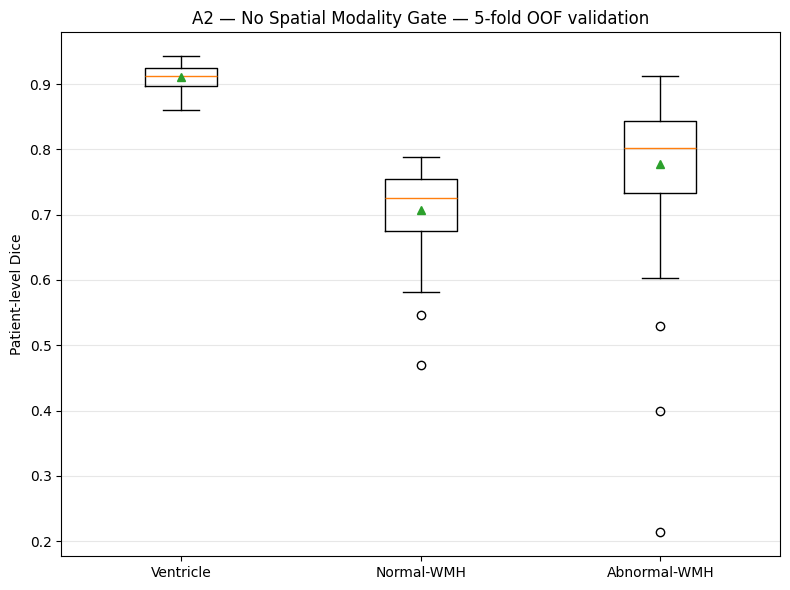

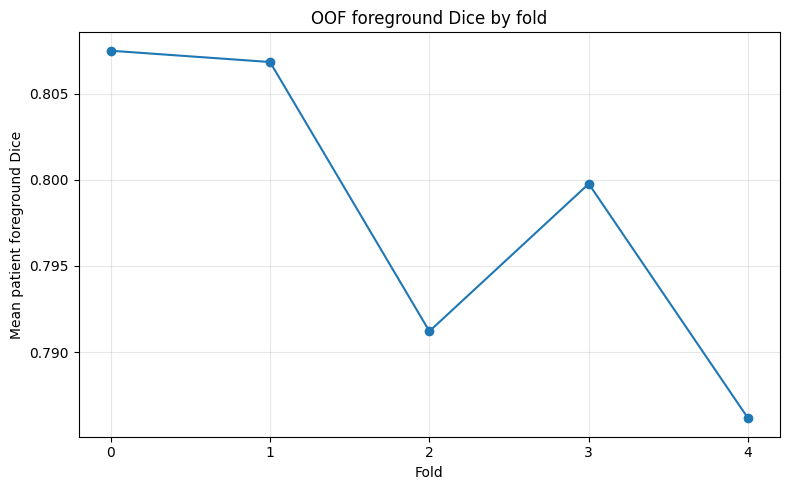

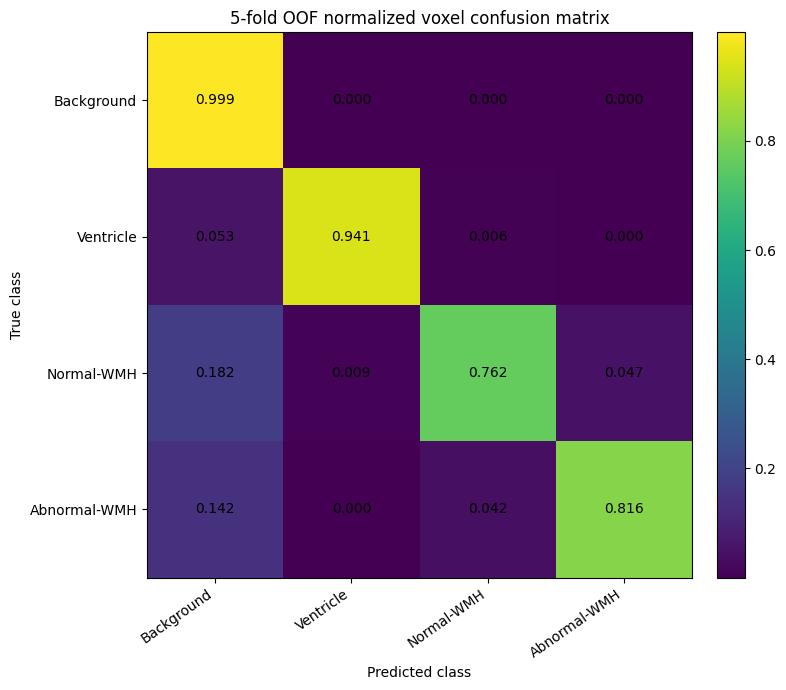

In [11]:
# Publication-oriented validation figures (raw OOF predictions only).
dice_columns = [
    "ventricle_dice",
    "normal_wmh_dice",
    "abnormal_wmh_dice",
]
labels = ["Ventricle", "Normal-WMH", "Abnormal-WMH"]

plt.figure(figsize=(8, 6))
plt.boxplot(
    [patient_metrics_df[c].dropna().values for c in dice_columns],
    labels=labels,
    showmeans=True,
)
plt.ylabel("Patient-level Dice")
plt.title("A2 — No Spatial Modality Gate — 5-fold OOF validation")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "a2_no_spatial_gate_5fold_oof_dice_boxplot.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    fold_summary["fold"],
    fold_summary["mean_fg_dice"],
    marker="o",
)
plt.xticks(range(5))
plt.xlabel("Fold")
plt.ylabel("Mean patient foreground Dice")
plt.title("OOF foreground Dice by fold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "a2_no_spatial_gate_oof_fg_dice_by_fold.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

normalized_confusion = (
    global_confusion
    / np.maximum(global_confusion.sum(axis=1, keepdims=True), 1)
)

plt.figure(figsize=(8, 7))
image = plt.imshow(normalized_confusion, interpolation="nearest")
plt.colorbar(image, fraction=0.046, pad=0.04)
axis_labels = ["Background", "Ventricle", "Normal-WMH", "Abnormal-WMH"]
plt.xticks(range(4), axis_labels, rotation=35, ha="right")
plt.yticks(range(4), axis_labels)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("5-fold OOF normalized voxel confusion matrix")
for r in range(4):
    for c in range(4):
        plt.text(c, r, f"{normalized_confusion[r, c]:.3f}", ha="center", va="center")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "a2_no_spatial_gate_5fold_oof_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


In [12]:
metadata = {
    "model": "A2 — No Spatial Modality Gate",
    "evaluation": "5-fold out-of-fold validation",
    "checkpoint_selection": "best_model.pt selected during training by balanced validation score",
    "folds": [0, 1, 2, 3, 4],
    "patients_per_fold": 16,
    "total_oof_patients": 80,
    "locked_test_patients": 20,
    "locked_test_evaluated": False,
    "split_sha256": EXPECTED_SPLIT_SHA256,
    "inference_rule": "argmax on segmentation_logits",
    "postprocessing_calibration": "none in this notebook",
    "lesion_matching": {
        "connectivity": "3D scipy structure rank 2",
        "minimum_component_voxels": 3,
        "iou_threshold": 0.10,
        "one_to_one_matching": "Hungarian assignment",
    },
}

(OUTPUT_DIR / "evaluation_metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

archive_path = shutil.make_archive(
    "/kaggle/working/MS3SEG_A2_NO_SPATIAL_GATE_5FOLD_OOF_VALIDATION_RESULTS",
    "zip",
    root_dir=OUTPUT_DIR,
)

print("\n5-fold OOF validation archive created:")
print(archive_path)
print("\nDownload this file:")
print(
    "/kaggle/working/"
    "MS3SEG_A2_NO_SPATIAL_GATE_5FOLD_OOF_VALIDATION_RESULTS.zip"
)
print("\nLocked-test patients evaluated: 0")



5-fold OOF validation archive created:
/kaggle/working/MS3SEG_A2_NO_SPATIAL_GATE_5FOLD_OOF_VALIDATION_RESULTS.zip

Download this file:
/kaggle/working/MS3SEG_A2_NO_SPATIAL_GATE_5FOLD_OOF_VALIDATION_RESULTS.zip

Locked-test patients evaluated: 0


## After this notebook finishes

Download `MS3SEG_A2_NO_SPATIAL_GATE_5FOLD_OOF_VALIDATION_RESULTS.zip` and upload it back here.

Do not run a final test or tune the model from the locked-test patients in this notebook.
